<h1>Matplotlib</h1>
<p>By: ImadElMaftouhi   </p>

In [1]:
# to install : pip install matplotlib
import matplotlib
print(matplotlib.__version__)
del matplotlib

3.11.2


In [2]:
#most of the matplotlib utilities reside under the pyplot submodule.
import matplotlib.pyplot as plt
import numpy as np

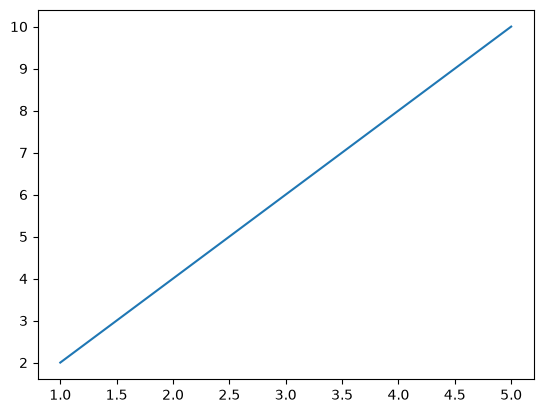

'\nthe plot() function is used to draw points in a diagram. By default, the plot() function draws a line from point to point.\n'

In [3]:
x = np.array([1,2,3,4,5])
y = np.array([2,4,6,8,10])
plt.plot(x,y)
plt.show()

"""
the plot() function is used to draw points in a diagram. By default, the plot() function draws a line from point to point.
"""

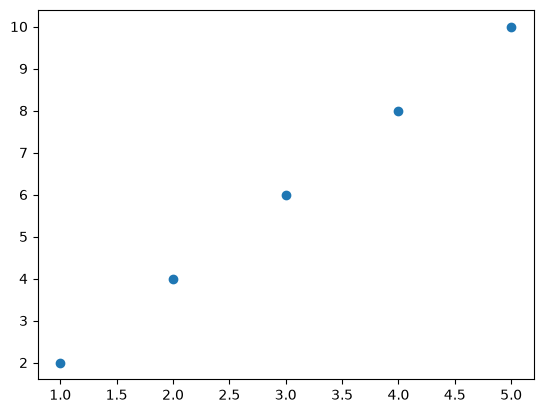

In [4]:
# we can also plot without any lines, just points, by specifying a 'o' as the third argument to the plot() function:
x = np.array([1,2,3,4,5])
y = np.array([2,4,6,8,10])
plt.plot(x,y,'o')
plt.show()

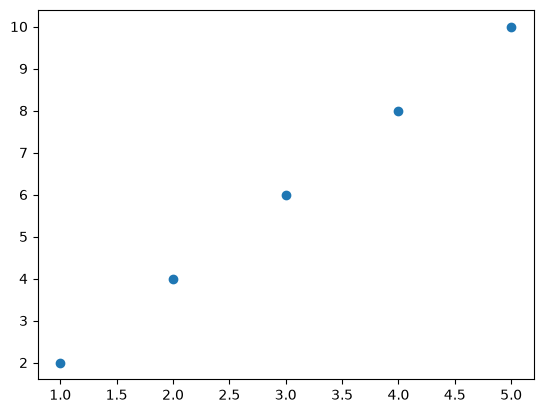

In [5]:
"""
if we do not want the points to be connected with a line, we can use the keyword argument linestyle and set it to 'none':
"""
x = np.array([1,2,3,4,5])
y = np.array([2,4,6,8,10])
plt.plot(x,y,linestyle='none',marker='o')  
plt.show()

In [6]:
"""
if we do not specify the points on the x-axis, they will get the default values 0,1,2,3,... .
"""

'\nif we do not specify the points on the x-axis, they will get the default values 0,1,2,3,... .\n'

## Markers

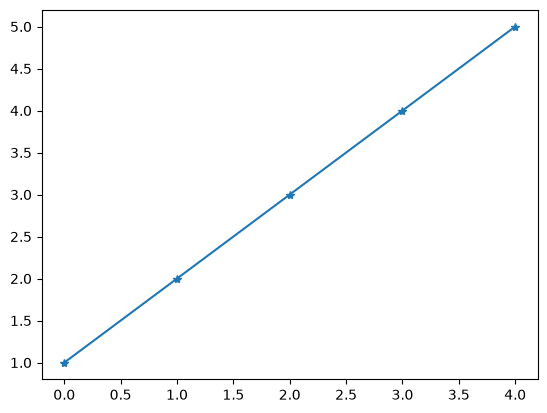

In [7]:
# we can use the keyword argument marker to emphasize each point with a specified marker.
# there are many markers available, such as 'o' for circle, '*' for star, '.' for point, ',' for pixel, 'x' for x, '+' for plus, '1' for tri_down, '2' for tri_up, '3' for tri_left, '4' for tri_right, 's' for square, 'p' for pentagon, 'h' for hexagon1, 'H' for hexagon2, and many more.

plt.plot(x, marker="*")

## Format string **fmt**

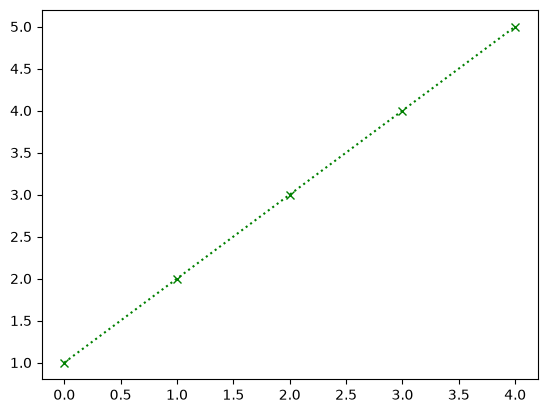

In [8]:
# the *fmt* parameter is the *shortcut string notation* parameter to specify the marker. the syntax is **marker|line|color**.

plt.plot(x, 'x:g') # x for marker, : for dotted line, g for green color

# line references : '-' for solid line, ':' for dotted line, '--' for dashed line, '-.' for dashdot line

# color references : 'b' for blue, 'g' for green, 'r' for red, 'c' for cyan, 'm' for magenta, 'y' for yellow, 'k' for black, 'w' for white

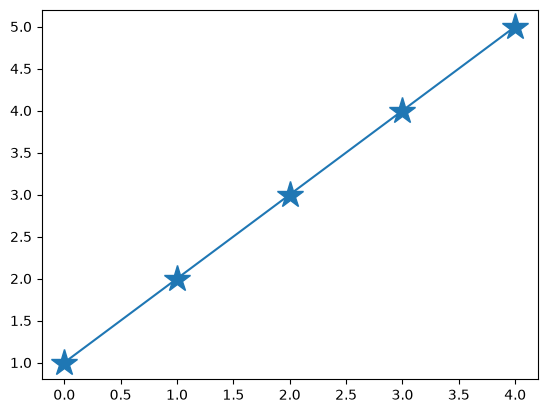

In [9]:
# we can also use the marker size parameter (*markersize* or *ms*) to set the size of the markers.

plt.plot(x, marker="*", ms=20) # set the size of the markers to 20

## Labels and Title 

In [10]:
"""
With pyplot, we can use the xlabel(), ylabel() and title() functions to set a label for the x- and y-axis, and a title for the graph respectively.

we can also set the font properties for titles and labels by using the *fontdict* parameter to set font properties.

Additionally, we can position the title how we want using the *loc* parameter. 
"""

'\nWith pyplot, we can use the xlabel(), ylabel() and title() functions to set a label for the x- and y-axis, and a title for the graph respectively.\n\nwe can also set the font properties for titles and labels by using the *fontdict* parameter to set font properties.\n\nAdditionally, we can position the title how we want using the *loc* parameter. \n'

## Grid lines

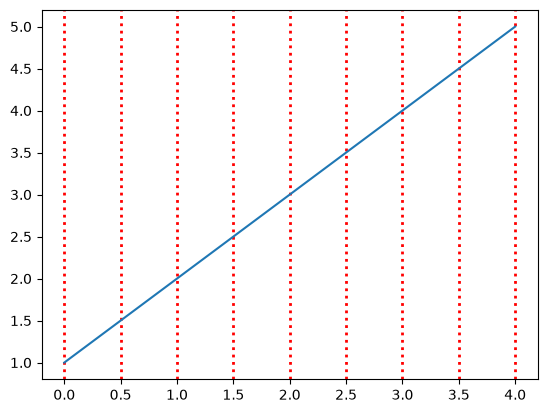

In [11]:
"""
we can use the grid() function to add grid lines to the plot. we can also use the *axis* parameter to specify which axis to apply the grid lines to. The *axis* parameter can take the following values: 'both', 'x', 'y', 'none'.
similar to plot(), we can also use the *linestyle* and *color* parameters to specify the style and color of the grid lines.
"""

plt.plot(x)
plt.grid(color="red",linestyle=":",linewidth=2,axis="x")

## Display Multiple Plots 

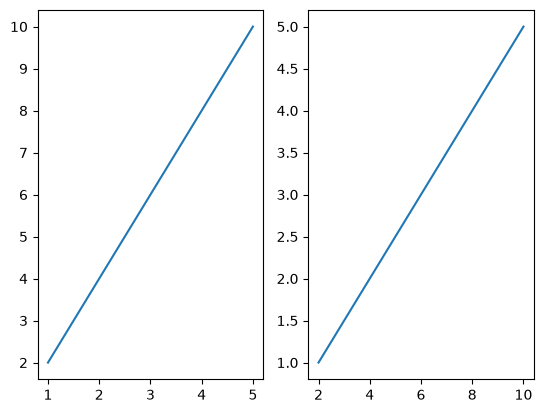

In [12]:
# we can use the subplot() method to draw multiple plots in one figure.

x = np.array([1,2,3,4,5])
y = np.array([2,4,6,8,10])

plt.subplot(1,2,1) # 1 row, 2 columns, first subplot
plt.plot(x,y)

plt.subplot(1,2,2)
plt.plot(y,x)

plt.show()

The phrase "multiple plots" covers four distinct arrangements, and the object model from the previous document tells you which one you want. You may want several data series drawn into a single axes, several axes tiled within one figure, inset or secondary axes layered over an existing axes, or several independent figures open at once. Each has a canonical construction, and conflating them is the usual source of confusion when a beginner writes plt.plot three times and gets one overlapping axes rather than a grid.

### Several series in one axes

repeated calls on the same axes accumulate artists. The obligations are perceptual distinction and a legend, nothing more. This is correct when the series share unites.

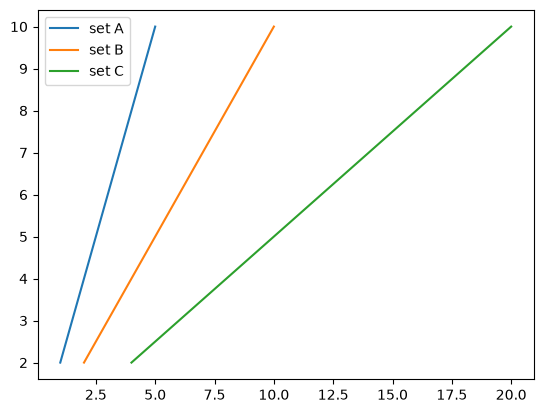

In [14]:
fig, ax = plt.subplots()
ax.plot(x,y, label="set A")
ax.plot(x*2,y, label="set B")
ax.plot(x*4,y, label="set C")
ax.legend()


### regular grid

Text(0.5, 0.01, 'X-Axis')

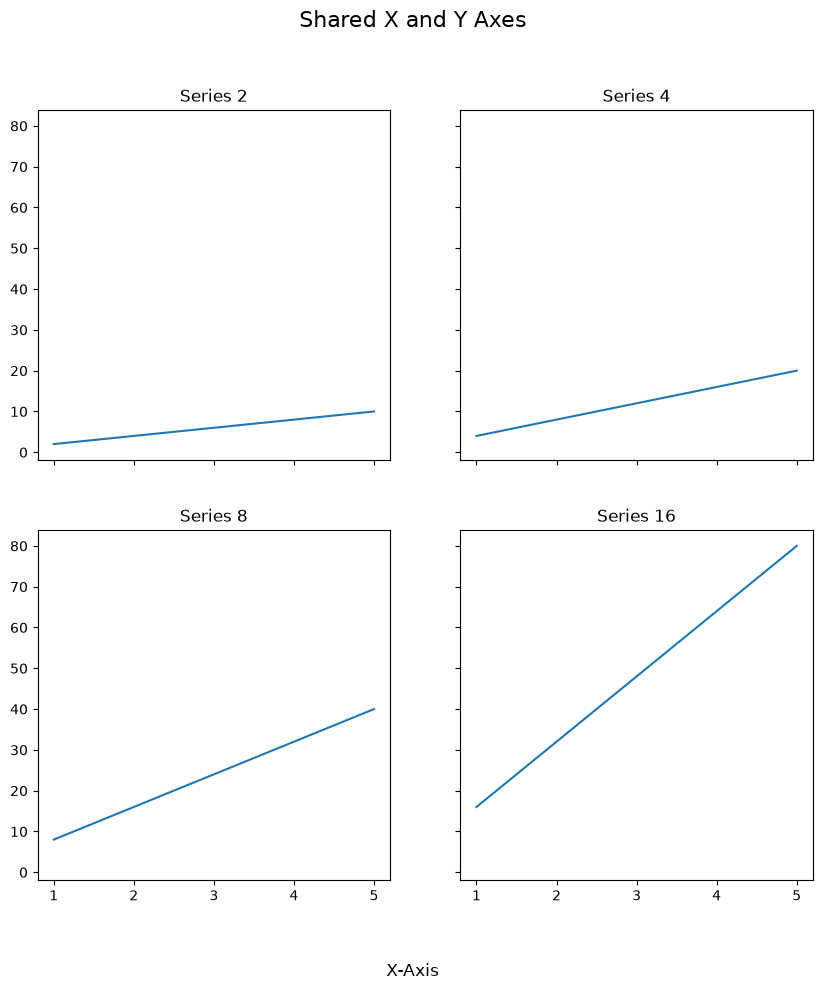

In [29]:
# When the series do not share units, we use the layering constructions below
# subplots returns an array of axes. Index it directly, or iterate over .flat to avoid repetitive blocks.

fig, axes = plt.subplots(2,2, figsize=(10,10), sharex=True, sharey=True)
for ax, series in zip(axes.flatten(), [y, y*2, y*4, y*8]):
    ax.plot(x, series)
    ax.set_title(f"Series {series[0]}")

for ax in axes.flat[4:]:
    ax.set_visible(False)

fig.suptitle("Shared X and Y Axes", fontsize=16)
fig.supxlabel("X-Axis")


## sharex and sharey suppress redundant interior tick labels, which is the difference between readbale and cluttered. Pass "squeeze=False" when writing a function that must handle & 1xN grid uniformly. Figure-level text belongin to suptitle and supxlabel, positioned in figure coordinates rather tha within one panel.

### irregular grids

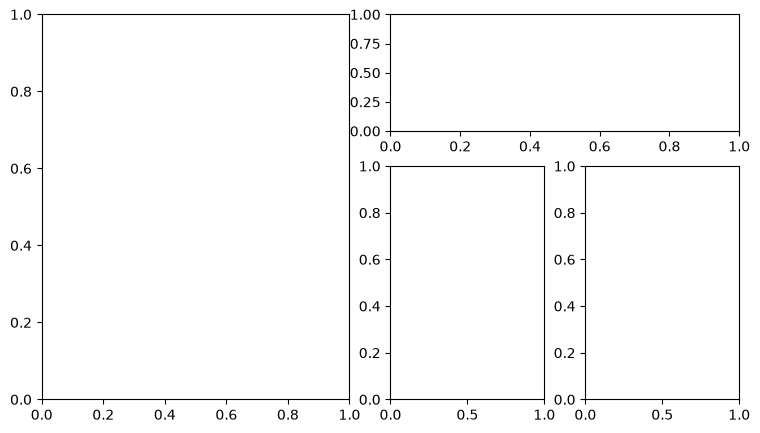

In [30]:
# 'GridSpec' allows unequal rows and colunns and axes spanning multiple cells; the slicing syntax mirrors numpy

fig = plt.figure(figsize=(9, 5))
gs = fig.add_gridspec(2, 3, width_ratios=[2, 1, 1], height_ratios=[1, 2])

ax_main = fig.add_subplot(gs[:, 0])      # full-height left column
ax_top  = fig.add_subplot(gs[0, 1:])     # top row, last two columns
ax_br   = fig.add_subplot(gs[1, 1])
ax_br2  = fig.add_subplot(gs[1, 2])

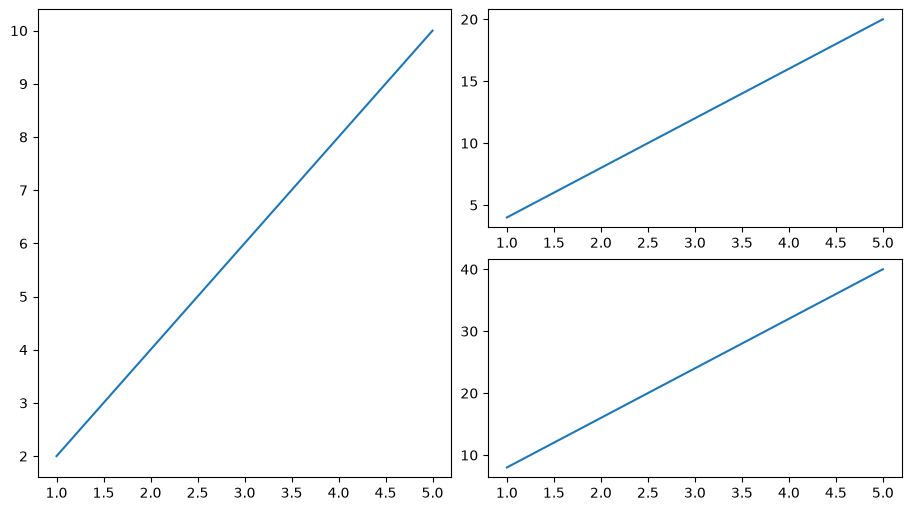

In [32]:
# 'subplot_mosaic' trades flexibility for legibility: the layout is visible in the source. Repeated charaters merge cells, and the return is a dictionnary keyed by name. for most hand-designed figures, 'subplot_mosaic' is the better choice because it removes index arithmetic from the reader's path.

fig, axd = plt.subplot_mosaic(
    [["left", "right_top"],
    ["left", "right_bottom"]],
    figsize=(9,5),
    layout="constrained"
)

axd["left"].plot(x,y)
axd["right_top"].plot(x,y*2)
axd["right_bottom"].plot(x,y*4)

### Absolute placement

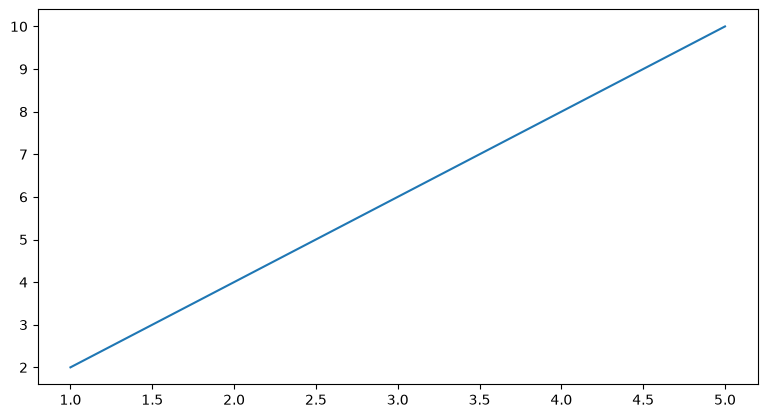

In [33]:
# add_axes places an axes at explicit figure-fraction coordinates. It forfeits automatic layout, so every margin is yours to maintain, and it is the tool of last resort.
fig = plt.figure(figsize=(9,5))

ax = fig.add_axes([0.12, 0.15, 0.8, 0.75])
ax.plot(x,y)

### layering within one region

Text(0, 0.5, 'temperature (F)')

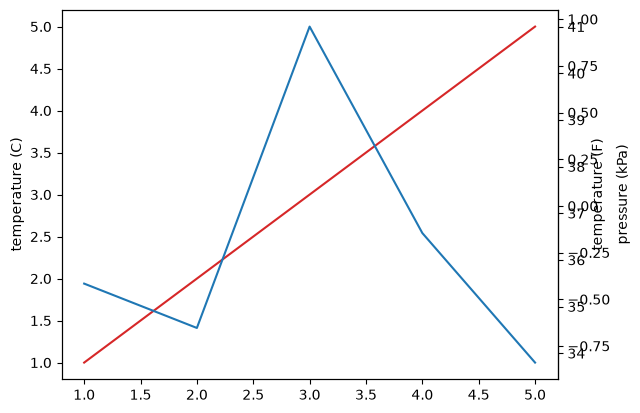

In [49]:
## 'twinx' adds a right-hand y-axis sharing the x-axis, the answer when two series share an x variable but differ in unites


fig, ax1 = plt.subplots()
ax1.plot(x, y*0.5, color="tab:red")
ax1.set_ylabel("temperature (C)")

ax2 = ax1.twinx()
ax2.plot(x, np.cos(y), color="tab:blue")
ax2.set_ylabel("pressure (kPa)")



In [52]:
## 'secondary_axis' produces the same visual result with an explicit forward and inverse transform, so the two scales cannot drift out of correspandance

## 'inset_axes' places a detail view inside the parent, addressed in the parent's axes coordinates, so it stays anchored under resizing.

## each of these is a first-class axes with its own limites, ticks and artists; nothing special keeps it aligned.

### Layout engines

In [61]:
# 'constrained_layout' runs an iterative solver at draw time, allocating space for ticks labels, axis,labels, colorbars and suptitles. It handles cases the defaut 'tight_layout', notably nested gridspecs and attached colorbars.

# fig, axes = plt.subplots(2, 2, layout="constrained")
# # or, after construction:
# fig.set_layout_engine("constrained")

## neither engine respect coordinates giver to add_axes, so the choice between automatic with a declarative grid and manual layout with explicit numbers. Mixing the produces the surprises that consume afternoons.

## If the panels share units, draw into one axes. If they form a grid, use subplots and iterate over the returned array. If the grid is irregular, declare it with subplot_mosaic or GridSpec. If a second scale is needed on the same x-range, use twinx or secondary_yaxis. If placement is truly arbitrary, use add_axes and accept the maintenance cost. Choose a layout engine once, at construction, and let it run. Everything else reduces to calling methods on axes objects you already hold.

## plotting functions

the plotting functions cluster by data shape and by the question asked, not alphabetically. Learning the clusters converts the catalogue into a decision procedure, and the decision is short: is the x-axis ordered or categorical, is the data a series, a distribution, a matrix, or a field ? Every function below exists both as plt.'fn' and as ax.'fn'; prefer the axes method for the reasons established earlier.

In [63]:
rng = np.random.default_rng(seed=42)
t = np.linspace(0, 10, 500)
y = np.sin(t)

### Ordered series: variantes of plot

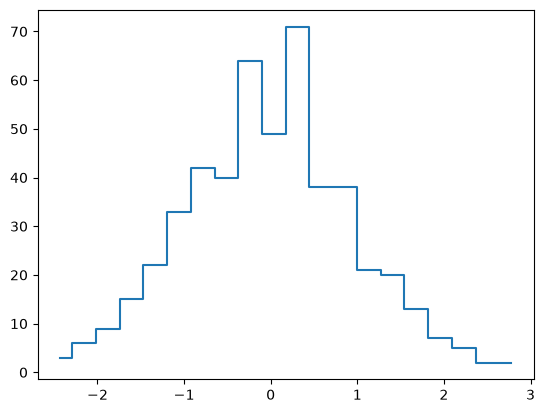

In [64]:
## 'step' draws the same data as 'plot' but holds each value until the next sample. Use it when the underlying signal is genuinely piecewise-constant, such as histogram bins or sampled digital signals, and plot would falsely imply linear interpolation.

counts, edges = np.histogram(rng.normal(size=500), bins=20)
centers = 0.5 * (edges[:-1] + edges[1:])

fig, ax = plt.subplots()
ax.step(centers, counts, where="mid")   # where in {'pre', 'post', 'mid'}

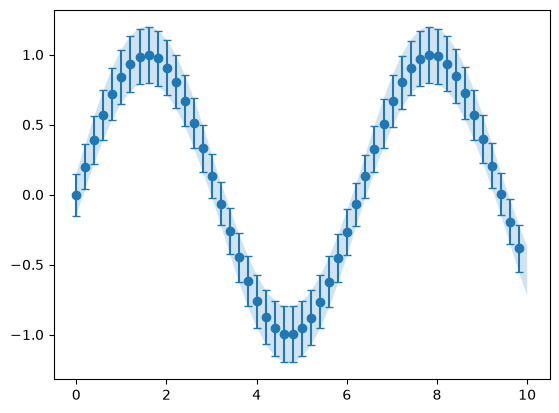

In [68]:
## 'errorbar' attaches per-point uncertainty, which plot cannot express. It accepts symmetric errors, asymmetric pairs, and per-point arrays, and fmt controls the marker and line style in the same syntax as plot.

fig, ax = plt.subplots()
yerr = 0.15 + 0.05 * np.abs(y)
ax.errorbar(t[::10], y[::10], yerr=yerr[::10], fmt="o", capsize=3)
ax.fill_between(t, y - yerr, y + yerr, alpha=0.2)

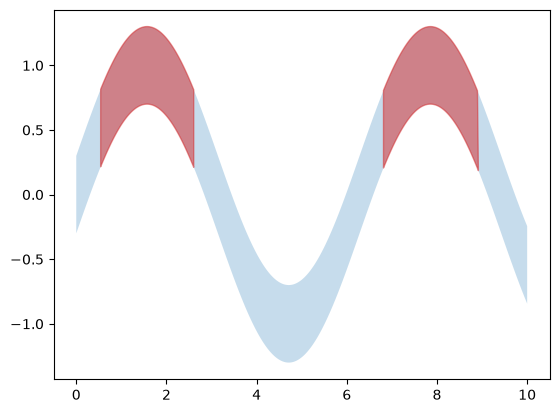

In [72]:
fig, ax = plt.subplots()
ax.fill_between(t, y - 0.3, y + 0.3, alpha=0.25, label="95% CI")
ax.fill_between(t, y - 0.3, y + 0.3, where=y > 0.5,
                color="tab:red", alpha=0.5, interpolate=True)

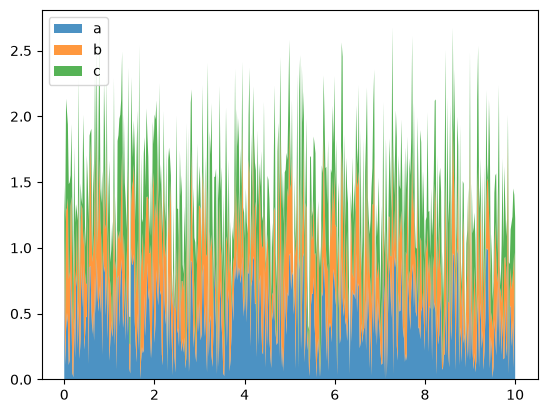

In [75]:
## stackplot shows composition over an ordered axis, accumulating series so that the total height is the sum. It answers the same question as a pie chart but for a variable that evolves.

fig,ax = plt.subplots()
components = rng.random((3, t.size))
ax.stackplot(t, components, labels=["a", "b", "c"], alpha=0.8)
ax.legend(loc="upper left")

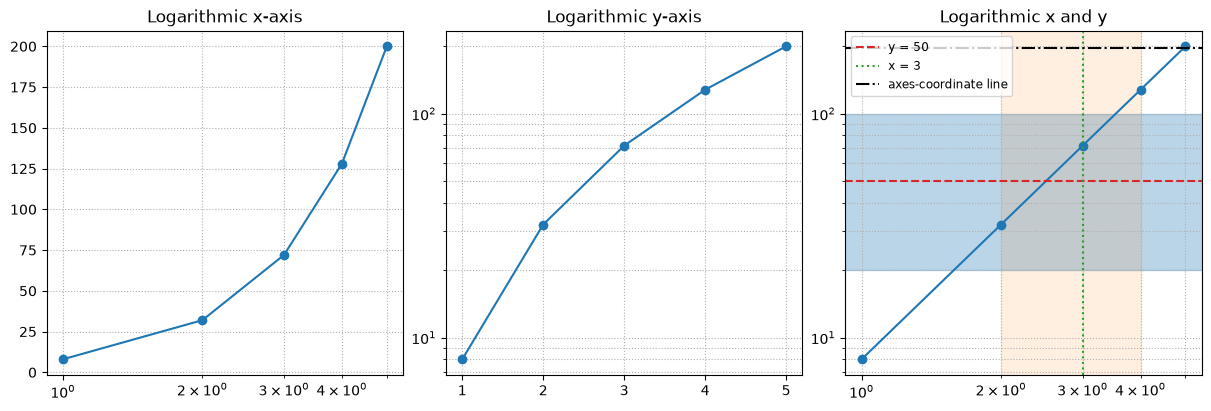

In [83]:
## semilogx, semilogy, and loglog are convenience wrappers around setting the scale. The general mechanism is ax.set_xscale("log"), which works on any axes after construction and composes with every function in this list.

## axhline, axvline, axhspan, and axvspan draw reference lines and shaded bands. Coordinates are in data units by default; pass transform=ax.transAxes for figure-fraction placement that survives changing limits.


fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")

axes[0].semilogx(x, series, marker="o")
axes[0].set_title("Logarithmic x-axis")

axes[1].semilogy(x, series, marker="o")
axes[1].set_title("Logarithmic y-axis")

ax = axes[2]
ax.loglog(x, series, marker="o")
ax.set_title("Logarithmic x and y")
ax.axhline(50, color="tab:red", linestyle="--", label="y = 50")
ax.axvline(3, color="tab:green", linestyle=":", label="x = 3")
ax.axhspan(20, 100, color="tab:blue", alpha=0.3)
ax.axvspan(2, 4, color="tab:orange", alpha=0.12)

# Plot in axes-fraction coordinates (from 0 to 1), independent of data limits.
ax.plot([0, 1], [0.95, 0.95], transform=ax.transAxes,
             color="black", linestyle="-.", label="axes-coordinate line")

for ax_i in axes:
    ax_i.grid(True, which="both", linestyle=":")

ax.legend(fontsize="small")
plt.show()


### Unordered points: scatter

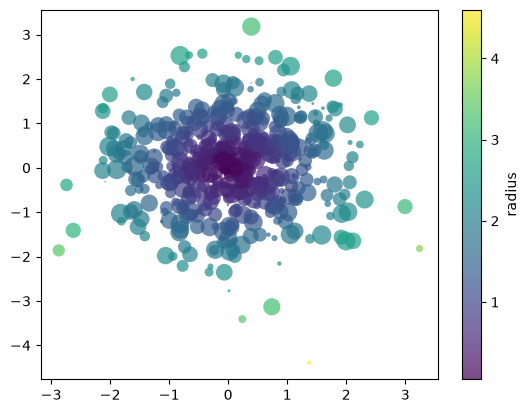

In [84]:
## plot with marker= and no linestyle returns a single Line2D with one color for the whole series. scatter returns a PathCollection and makes per-point color and size first-class by accepting arrays for c and s. Choose scatter when the points carry a third variable; choose plot when they do not, because plot is roughly an order of magnitude faster for large N and the color cycle handles distinction between series for you.

x, y2 = rng.normal(size=(2, 500))
radius = np.hypot(x, y2)
size = 200 * rng.random(500)

fig, ax = plt.subplots()
sc = ax.scatter(x, y2, c=radius, s=size, cmap="viridis", alpha=0.7,
                edgecolors="none")
fig.colorbar(sc, ax=ax, label="radius")

### categorical magnitudes: bar and barh

Text(0, 0.5, 'response (ms)')

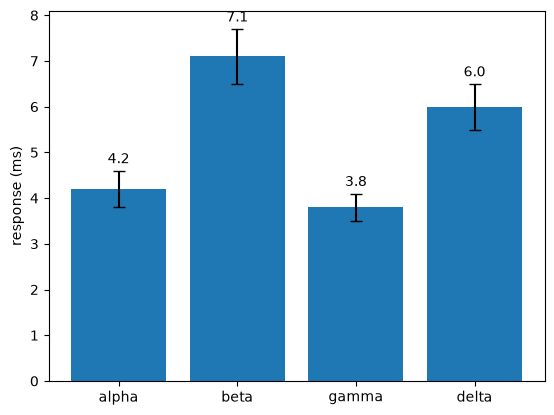

In [87]:
## bar and barh draw magnitudes against discrete categories, and the orientation is not cosmetic: barh is the correct choice when category names are long enough to collide on a horizontal axis. bar_label, available since 3.4, annotates the bars and has replaced the manual loop over ax.text.

categories = ["alpha", "beta", "gamma", "delta"]
values = [4.2, 7.1, 3.8, 6.0]
errs = [0.4, 0.6, 0.3, 0.5]

fig, ax = plt.subplots()
bars = ax.bar(categories, values, yerr=errs, capsize=4, color="tab:blue")
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_ylabel("response (ms)")

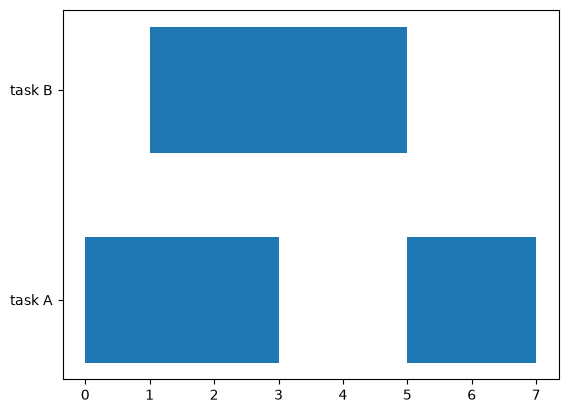

In [89]:
## 'broken_barh' draws Gantt-style intervals from a list of (start,width) tuple, which is the right tool fr schedules and state timelines

fig,ax = plt.subplots()
intervals = [("task A", [(0, 3), (5, 2)]), ("task B", [(1, 4)])]
for i, (name, spans) in enumerate(intervals):
    ax.broken_barh(spans, (i - 0.3, 0.6))
ax.set_yticks(range(len(intervals)), [n for n, _ in intervals])

### Distributions: hist, boxplot, violinplot, eventplot

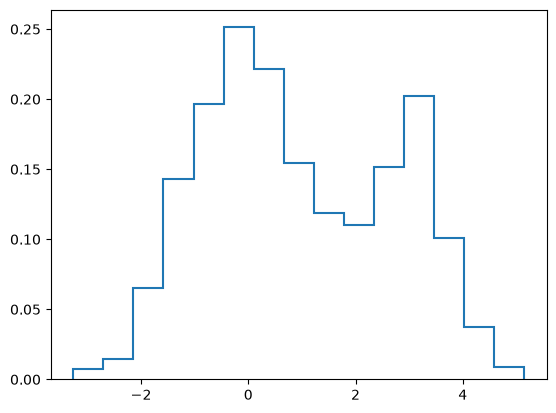

In [93]:
## hist bins a sample and draws counts or density. bins="auto" delegates the choice to a rule, density=True normalizes to unit area so samples of different size are comparable, and histtype="step" makes overlaid distributions legible in a way that filled bars do not.

fig,ax=plt.subplots()
data = np.concatenate([rng.normal(0, 1, 800), rng.normal(3, 0.7, 400)])
ax.hist(data, bins="auto", density=True, histtype="step", linewidth=1.5)
plt.show()

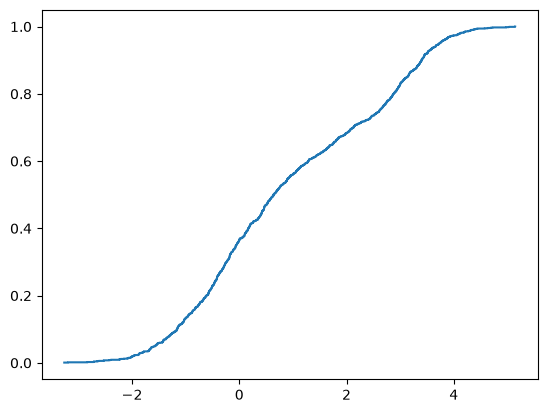

In [ ]:
## Matplotlib has no ecdf function, and this is the one gap worth filling by hand. The empirical cumulative distribution involves no binning decision, so it avoids the arbitrary choice that a histogram imposes, and it is three lines.

fig,ax=plt.subplots()
xs = np.sort(data)
ys = np.arange(1, xs.size + 1) / xs.size
ax.step(xs, ys, where="post")
plt.show()



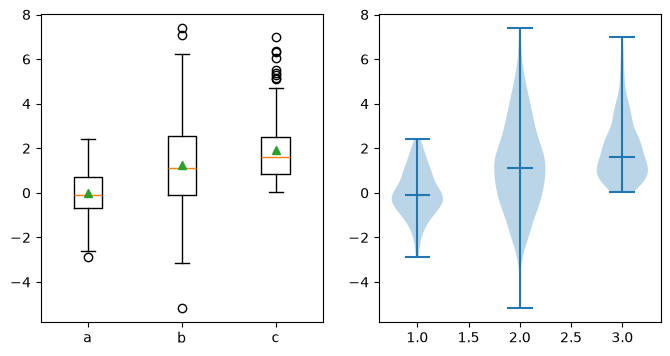

In [96]:
## boxplot summarizes each group by median, quartiles, and outliers, and it remains honest at small sample sizes because it summarizes rather than estimates. violinplot estimates the full kernel density and shows shape that the box hides, but it requires enough samples per group for the estimate to mean anything. The labels argument was renamed tick_labels in 3.9.

samples = [rng.normal(0, 1, 200), rng.normal(1, 2, 200), rng.gamma(2, 1, 200)]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].boxplot(samples, tick_labels=["a", "b", "c"], showmeans=True)
axes[1].violinplot(samples, showmedians=True)
plt.show()


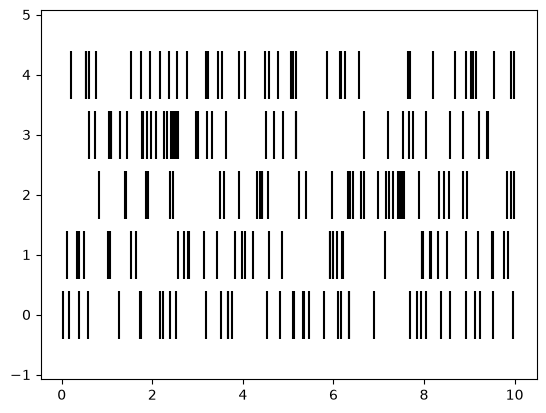

In [97]:
## eventplot renders discrete occurrences per channel as a raster, which is the natural display for spike trains, log timestamps, and any data whose interesting structure is the timing of events rather than their magnitude.

fig,ax=plt.subplots()
events = [np.sort(rng.random(40)) * 10 for _ in range(5)]
ax.eventplot(events, colors="black", lineoffsets=range(5), linelengths=0.8)
plt.show()

### Two-dimensional density: hist2d and hexbin

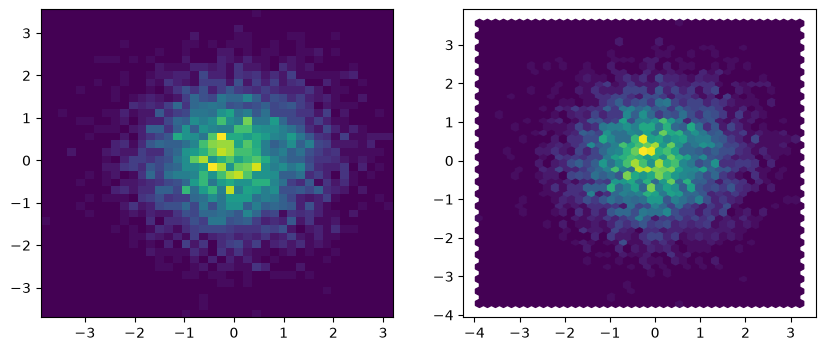

In [ ]:
##  When scatter saturates into an opaque blob, bin the plane instead. hist2d uses rectangular bins and shows grid artifacts at lw occupancy; hexbin uses hexagonal bins, which tile more uniformly in distance and impose less directional bias on the eye. Both return a mappable, so a colorbar follows directly.

x, y3 = rng.normal(size=(2, 5000))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist2d(x, y3, bins=40, cmap="viridis")
axes[1].hexbin(x, y3, gridsize=40, cmap="viridis")

### matrices and images: imshow, pcolormesh, spy

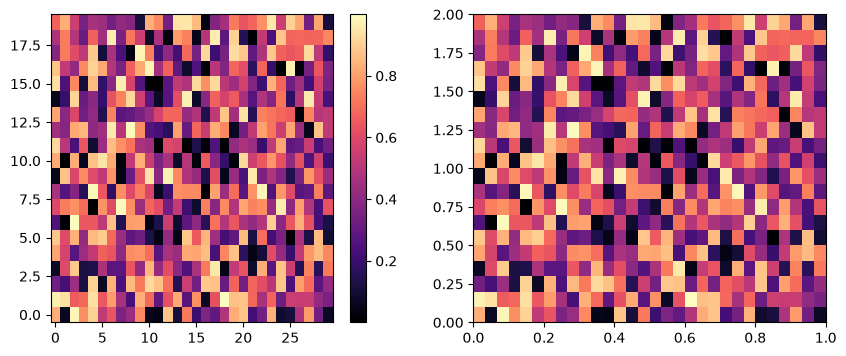

In [ ]:
## imshow renders a regularly sampled array and owns the decisions about aspect ratio, interpolation, and origin. Set origin="lower" whenever the array follows matrix indexing, or the vertical axis will be inverted relative to every other convention in your code.

matrix = rng.random((20, 30))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im = axes[0].imshow(matrix, cmap="magma", origin="lower", aspect="auto")
fig.colorbar(im, ax=axes[0])

axes[1].pcolormesh(np.linspace(0, 1, 31), np.linspace(0, 2, 21),
                   matrix, shading="auto", cmap="magma")

## pcolormesh takes explicit x and y edge arrays, so it handles non-uniform and curvilinear grids that imshow cannot. pcolor is the legacy variant: it is slower and silently drops the last row and column. spy displays the sparsity pattern of a matrix and is the correct tool for adjacency matrices and Jacobians, where the question is where the nonzeros are, not what they equal.

### scalar and vector fields, contour, contourf, quiver, streamplot

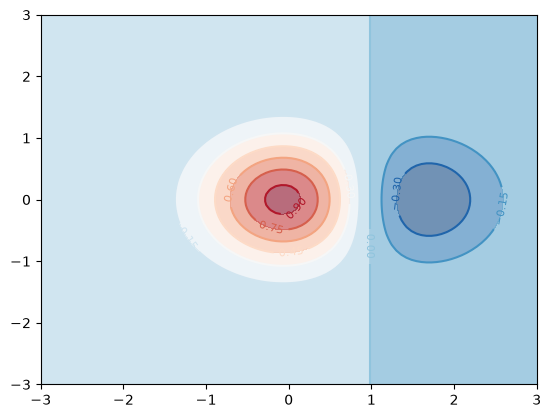

In [100]:
## contour draws iso-lines of a scalar field and contourf fills between them; combining the two, filled at low alpha with labeled lines on top, reads better than either alone. clabel annotates the lines inline, and explicit levels are essential when comparing panels, because automatic level selection differs between them.

X, Y = np.meshgrid(np.linspace(-3, 3, 100), np.linspace(-3, 3, 100))
Z = np.exp(-(X**2 + Y**2)) - 0.5 * np.exp(-((X - 1.5)**2 + Y**2))

fig, ax = plt.subplots()
cs = ax.contour(X, Y, Z, levels=12, cmap="RdBu_r")
ax.clabel(cs, inline=True, fontsize=8)
ax.contourf(X, Y, Z, levels=12, cmap="RdBu_r", alpha=0.6)

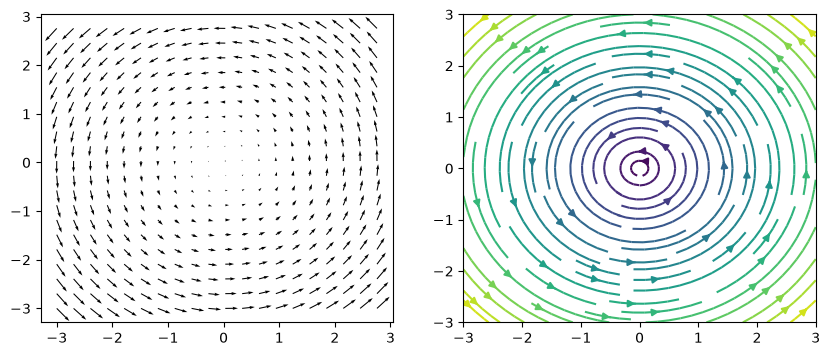

In [101]:
## quiver draws arrows at grid points and its scale parameter sets arrow length per data unit; subsample a dense grid or the figure becomes a solid mass. streamplot draws integral curves of the field and encodes magnitude in linewidth and color, which reads better for continuous flows. barbs is the meteorological variant for wind fields.

U, V = -Y, X
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].quiver(X[::5, ::5], Y[::5, ::5], U[::5, ::5], V[::5, ::5])
axes[1].streamplot(X, Y, U, V, color=np.hypot(U, V), cmap="viridis")


### Spectral and correlation: psd, specgram, acorr, xcorr

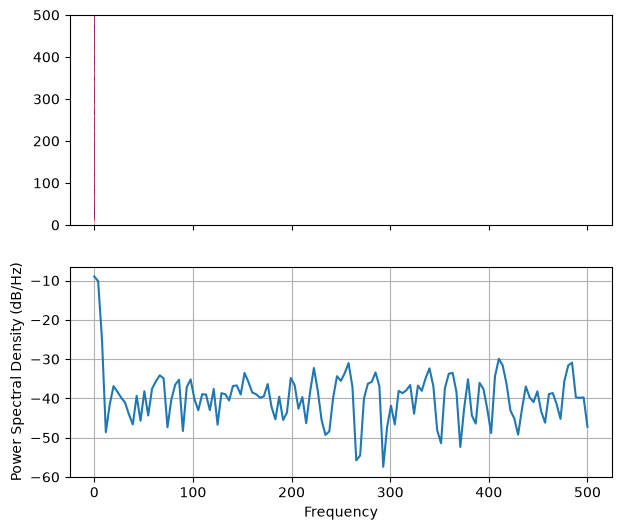

In [103]:
## psd, specgram, acorr, xcorr, cohere, csd, magnitude_spectrum, and phase_spectrum wrap the routines in matplotlib.mlab. specgram gives the time-frequency plane, psd the averaged spectrum, acorr the autocorrelation. For anything beyond quick inspection, call scipy.signal.welch or scipy.signal.spectrogram and plot the returned arrays explicitly, because that route exposes the window, overlap, and detrending choices that the pyplot wrappers bury.

fs = 1000
sig = np.sin(2 * np.pi * 50 * t) + 0.3 * rng.normal(size=t.size)

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
axes[0].specgram(sig, Fs=fs, NFFT=256, noverlap=128, cmap="magma")
axes[1].psd(sig, Fs=fs)
plt.show()


### Composition: pie

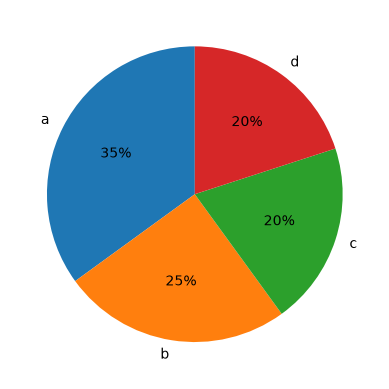

In [105]:
## pie exists and is widely overused. Human perception compares angles poorly, so a bar chart communicates the same part-to-whole data more accurately in almost every case. Reserve pie for three to five categories with a clear ordering, and reach for a stacked bar or a table otherwise.

fig,ax=plt.subplots()
ax.pie([35, 25, 20, 20], labels=["a", "b", "c", "d"],
       autopct="%1.0f%%", startangle=90)
plt.show()